# Vectorized likelihoods: NumPy, JAX and threads

Every iteration, `PTSampler` evaluates the likelihood once for each
temperature chain. By default that's one Python call per chain. This
notebook shows three ways to make that step faster, on the sinusoid model
from the [quickstart](sinusoid_quickstart.ipynb):

1. **Vectorized NumPy** (`vectorized=True`): one call per iteration with
   all chains as a batch.
2. **JAX** (`vectorized=True, jax=True`): the same batch through a
   JIT-compiled function, including the one setting you must not forget.
3. **Threads** (`threads=n`): keep a per-row likelihood and evaluate the
   chains on a thread pool.

It ends with timings across data sizes and numbers of temperatures, and
when to use which. Besides `impulse-mcmc`, it uses `matplotlib` and `jax`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from impulse import PTSampler

TRUTH = np.array([1.0, 1.3, 0.7])  # amplitude, frequency (Hz), phase (rad)
LOW = np.array([0.0, 0.05, 0.0])
HIGH = np.array([5.0, 5.0, 2 * np.pi])
SIGMA = 1.0


def make_data(n, seed=23, duration=10.0):
    rng = np.random.default_rng(seed)
    t = np.linspace(0.0, duration, n, endpoint=False)
    signal = TRUTH[0] * np.sin(2 * np.pi * TRUTH[1] * t + TRUTH[2])
    return t, signal + SIGMA * rng.standard_normal(n)


t, data = make_data(1000)

## Per-row: one parameter vector per call

The quickstart's functions take one vector `x` of shape `(3,)`.

In [2]:
def make_per_row(t, data):
    def log_likelihood(x):
        a, f, phi = x
        residual = data - a * np.sin(2 * np.pi * f * t + phi)
        return -0.5 * np.dot(residual, residual) / SIGMA**2

    return log_likelihood


def log_prior(x):
    return 0.0 if np.all((x >= LOW) & (x <= HIGH)) else -np.inf

## Vectorized NumPy: all chains in one call

With `vectorized=True` the sampler passes a batch `x` of shape
`(n, 3)`, one row per chain, and expects `n` log densities back. Slicing
columns as `x[:, 0:1]` keeps them 2-D, so they broadcast against the
`(n_data,)` time array to give an `(n, n_data)` signal array.

The prior is evaluated first, and in plain NumPy mode the likelihood only
receives rows inside the prior.

In [3]:
def make_vectorized(t, data):
    def log_likelihood(x):
        a, f, phi = x[:, 0:1], x[:, 1:2], x[:, 2:3]
        residual = data - a * np.sin(2 * np.pi * f * t + phi)
        return -0.5 * np.einsum("ij,ij->i", residual, residual) / SIGMA**2

    return log_likelihood


def log_prior_vectorized(x):
    inside = np.all((x >= LOW) & (x <= HIGH), axis=1)
    return np.where(inside, 0.0, -np.inf)


per_row, vectorized = make_per_row(t, data), make_vectorized(t, data)
batch = np.random.default_rng(0).uniform(LOW, HIGH, size=(100, 3))
difference = np.array([per_row(x) for x in batch]) - vectorized(batch)
print(f"largest relative difference: {np.max(np.abs(difference / vectorized(batch))):.1e}")

largest relative difference: 1.2e-15


The two versions agree to rounding, but not bit for bit: the sums run in a
different order. Chains from the same seed therefore match only as long as
no accept decision lands within rounding of its threshold. That is
vanishingly rare, and in this run it never happens:

In [4]:
common = dict(ndim=3, ntemps=8, seed=1, verbose=False)

row_sampler = PTSampler(lnlike=per_row, lnprior=log_prior, outdir="chains_rows", **common)
row_sampler.sample(TRUTH, num_iterations=20_000)

vec_sampler = PTSampler(
    lnlike=vectorized,
    lnprior=log_prior_vectorized,
    vectorized=True,
    outdir="chains_vectorized",
    **common,
)
vec_sampler.sample(TRUTH, num_iterations=20_000)

same = np.array_equal(row_sampler.load_chain()["samples"], vec_sampler.load_chain()["samples"])
print("identical chains:", same)

identical chains: True


## JAX

JAX compiles the batched likelihood with `jax.jit` and fuses the sine,
subtraction, square and sum into one pass over the data, using several
CPU threads (or a GPU).

### First: enable 64-bit floats

**By default JAX computes in 32-bit floats, and it converts your float64
NumPy arrays to float32 without any warning.** A float32 number has about
7 significant digits. That is enough for this toy model, but not for time
stamps on an absolute clock: at a GPS time of $1.4 \times 10^9$ s,
neighbouring float32 values are 128 s apart.

In [5]:
t_gps = 1.4e9 + t  # the same 10 s of data, time-stamped in GPS seconds
print("distinct time stamps in float64:", np.unique(t_gps).size)
print("distinct time stamps in float32:", np.unique(t_gps.astype(np.float32)).size)

distinct time stamps in float64: 1000
distinct time stamps in float32: 1


In float32, all 1,000 samples land on the same time stamp, so every phase
$2\pi f t$ is the same number and the likelihood is meaningless. Nothing
fails or warns; the sampler just samples the wrong posterior.

The fix is one line, run **before** any JAX arrays are created:

In [6]:
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
print("JAX default float:", jnp.zeros(1).dtype)

JAX default float: float64


Subtracting a reference epoch from your times also helps, but enabling
64-bit floats protects every array, including ones you didn't think about.

### The JAX likelihood

Pass `jax=True` together with `vectorized=True`. The sampler then always
sends the full `(ntemps, 3)` batch, including rows outside the prior, and
discards those results afterwards. Skipping rows would change the batch
shape, and each new shape makes `jax.jit` compile again.

In [7]:
def make_jax(t, data):
    t, data = jnp.asarray(t), jnp.asarray(data)

    @jax.jit
    def log_likelihood(x):
        a, f, phi = x[:, 0:1], x[:, 1:2], x[:, 2:3]
        residual = data - a * jnp.sin(2 * jnp.pi * f * t + phi)
        return -0.5 * jnp.sum(residual * residual, axis=1) / SIGMA**2

    return log_likelihood


jax_likelihood = make_jax(t, data)
difference = np.asarray(jax_likelihood(batch)) - vectorized(batch)
relative = np.abs(difference / vectorized(batch))
print(f"largest relative difference from NumPy: {relative.max():.1e}")

jax_sampler = PTSampler(
    lnlike=jax_likelihood,
    lnprior=log_prior_vectorized,
    vectorized=True,
    jax=True,
    outdir="chains_jax",
    **common,
)
jax_sampler.sample(TRUTH, num_iterations=20_000)
jax_posterior = jax_sampler.load_chain()["samples"][0][5_000:]
row_posterior = row_sampler.load_chain()["samples"][0][5_000:]
print("posterior mean, per-row:", row_posterior.mean(axis=0).round(4))
print("posterior mean, JAX:    ", jax_posterior.mean(axis=0).round(4))

largest relative difference from NumPy: 1.3e-15


posterior mean, per-row: [0.9925 1.3009 0.709 ]
posterior mean, JAX:     [0.9925 1.3009 0.709 ]


## Threads

If the likelihood can't be vectorized, `threads=n` evaluates the per-row
function for the chains on a pool of `n` threads. This only helps when the
likelihood releases Python's global interpreter lock while it works, as
NumPy does on large arrays and as most compiled extensions do.

## Timings

Milliseconds per iteration for each approach, over short runs. The
numbers depend on your machine; the pattern is what matters. Each JAX
function is called once before timing, so compilation isn't counted.

In [8]:
def ms_per_iteration(lnlike, lnprior, ntemps, iterations, **options):
    sampler = PTSampler(
        ndim=3,
        lnlike=lnlike,
        lnprior=lnprior,
        ntemps=ntemps,
        seed=3,
        outdir="chains_timing",
        verbose=False,
        **options,
    )
    start = time.perf_counter()
    sampler.sample(TRUTH, num_iterations=iterations)
    return 1e3 * (time.perf_counter() - start) / iterations


results = {}
for ntemps in (8, 32):
    for n_data in (100, 1_000, 100_000):
        t_n, data_n = make_data(n_data)
        iterations = 2_000 if n_data <= 1_000 else 200
        jax_n = make_jax(t_n, data_n)
        jax_n(np.tile(TRUTH, (ntemps, 1))).block_until_ready()  # compile first
        results[ntemps, n_data] = {
            "per-row": ms_per_iteration(make_per_row(t_n, data_n), log_prior, ntemps, iterations),
            "threads=4": ms_per_iteration(
                make_per_row(t_n, data_n), log_prior, ntemps, iterations, threads=4
            ),
            "vectorized": ms_per_iteration(
                make_vectorized(t_n, data_n),
                log_prior_vectorized,
                ntemps,
                iterations,
                vectorized=True,
            ),
            "JAX": ms_per_iteration(
                jax_n, log_prior_vectorized, ntemps, iterations, vectorized=True, jax=True
            ),
        }

methods = list(next(iter(results.values())))
print(f"{'ntemps':>6} {'n_data':>8} " + " ".join(f"{m:>11}" for m in methods))
for (ntemps, n_data), row in results.items():
    print(f"{ntemps:>6} {n_data:>8} " + " ".join(f"{row[m]:>11.3f}" for m in methods))

ntemps   n_data     per-row   threads=4  vectorized         JAX
     8      100       0.095       0.394       0.067       0.099
     8     1000       0.125       0.423       0.104       0.120
     8   100000       2.775       1.131       4.339       0.833
    32      100       0.287       0.675       0.159       0.180
    32     1000       0.375       1.214       0.296       0.285
    32   100000      10.266       4.020      11.594       3.081


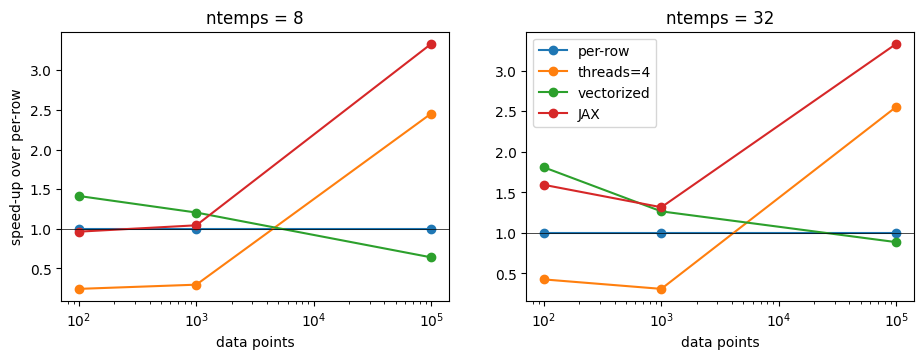

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=False)
for ax, ntemps in zip(axes, (8, 32)):
    sizes = [n for (nt, n) in results if nt == ntemps]
    for method in methods:
        speedup = [results[ntemps, n]["per-row"] / results[ntemps, n][method] for n in sizes]
        ax.plot(sizes, speedup, "o-", label=method)
    ax.axhline(1, color="k", lw=0.5)
    ax.set(xscale="log", xlabel="data points", title=f"ntemps = {ntemps}")
axes[0].set_ylabel("speed-up over per-row")
axes[1].legend();

## Which one to use

- **Cheap likelihood, many temperatures:** vectorized NumPy. The cost is
  dominated by one Python call per chain, and batching removes it.
- **Expensive likelihood:** JAX. Compilation fuses the work into one pass
  and runs it on several threads; plain NumPy batching can even be slower
  here, because it builds large temporary arrays. Always enable 64-bit
  floats.
- **Can't vectorize:** `threads=n`, provided the likelihood releases the
  global interpreter lock. On cheap likelihoods the thread pool's overhead
  makes it slower.
- The sampler itself costs a fraction of a millisecond per iteration
  (proposals, swaps, bookkeeping), so for a very cheap likelihood no
  option gets much below that floor.